**Assignment no. 2: Feature Engineering**

---


Scrap and create your own dataset, do feature engineering on dataset (encoding), and use data visualization.

**Name:** Tejas Narayan Mahamuni

**PRN:** 202401040036

**Roll No.** 7

**Github Link:** https://github.com/tejas-mahamuni/machine-learning.git


In [1]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime

# URL of fantasy premier league for scrapping dataset
URL = "https://fantasy.premierleague.com/api/bootstrap-static/"

response = requests.get(URL, timeout=60)
response.raise_for_status()

# storing response data
raw = response.json()

# players data
players = pd.DataFrame(raw["elements"])

# teams data
teams_table = pd.DataFrame(raw["teams"])

# position data
position_table = pd.DataFrame(raw["element_types"])

print(f"Scraped {len(players)} players from FPL API")

# columns required for player dataset
cols = [
    "first_name", "second_name", "team", "element_type", "birth_date",
    "now_cost", "minutes", "starts", "total_points", "points_per_game",
    "form", "goals_scored", "assists", "clean_sheets", "goals_conceded",
    "own_goals", "penalties_saved", "penalties_missed", "yellow_cards",
    "red_cards", "saves", "bonus", "bps", "influence", "creativity",
    "threat", "ict_index", "expected_goals", "expected_assists",
    "expected_goal_involvements", "expected_goals_conceded",
    "defensive_contribution", "tackles", "recoveries",
    "clearances_blocks_interceptions", "selected_by_percent", "dreamteam_count",
]

df = players[cols].copy()

# Map actual team name from team_table
df["team"] = df["team"].map(dict(zip(teams_table["id"], teams_table["name"])))

# Map actual position name from position_table
df["position"] = df["element_type"].map(dict(zip(position_table["id"], position_table["singular_name_short"])))

df = df.drop(columns=["element_type"])

# Store columns whose datatype is numeric but JSON returns them as string
num_cols = df.columns.difference(["first_name", "second_name", "team", "position", "birth_date"])

# Convert numeric columns into numeric format datatype
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")

# Convert price from FPL tenths to millions
df["price_m"] = df["now_cost"] / 10.0
df = df.drop(columns=["now_cost"])

# Keep players with at least one full match played
df = df[df["minutes"] >= 90].reset_index(drop=True)

print(f"After cleaning: {df.shape[0]} players x {df.shape[1]} columns")
print("Positions:", df["position"].value_counts().to_dict())
print("Null values:", int(df.isna().sum().sum()))

# Minutes-based per-90 rates computed (not pre-made per-90 columns)
for col in ["goals_scored", "assists", "expected_goals", "expected_assists",
          "expected_goal_involvements", "saves", "tackles", "recoveries",
          "defensive_contribution", "clearances_blocks_interceptions"]:
    df[f"{col}_per90"] = np.where(df["minutes"] > 0, df[col] / df["minutes"] * 90, 0.0)

# Age at season start
df["age"] = (pd.Timestamp("2025-08-01") - pd.to_datetime(df["birth_date"])).dt.days / 365.25
df = df.drop(columns=["birth_date"])

# Goal involvement overperformance (finishing skill proxy)
df["npxg_overperformance"] = df["goals_scored"] - df["expected_goals"]

# Label file with the live season the API is currently serving

out_file = f"pl_players_26-27.csv"
df.to_csv(out_file, index=False)

print("Saved ->", out_file)
df.head(10)

Scraped 667 players from FPL API
After cleaning: 330 players x 37 columns
Positions: {'MID': 148, 'DEF': 126, 'FWD': 32, 'GKP': 24}
Null values: 0
Saved -> pl_players_26-27.csv


,first_name,second_name,team,minutes,starts,total_points,points_per_game,form,goals_scored,assists,...,expected_goals_per90,expected_assists_per90,expected_goal_involvements_per90,saves_per90,tackles_per90,recoveries_per90,defensive_contribution_per90,clearances_blocks_interceptions_per90,age,npxg_overperformance
0,David,Raya Martín,Arsenal,540,6,33,5.5,1.3,0,0,...,0.000000,0.001667,0.001667,2.166667,0.166667,11.833333,0.000000,1.166667,29.878166,0.00
1,Gabriel,dos Santos Magalhães,Arsenal,540,6,27,4.5,1.0,0,0,...,0.085000,0.035000,0.120000,0.000000,1.000000,3.000000,7.666667,6.666667,27.616701,-0.51
2,Jurriën,Timber,Arsenal,131,1,2,0.7,0.3,0,0,...,0.000000,0.054962,0.054962,0.000000,2.061069,5.496183,4.122137,2.061069,24.123203,0.00
3,Myles,Lewis-Skelly,Arsenal,333,5,11,2.2,0.7,0,0,...,0.048649,0.156757,0.205405,0.000000,0.270270,2.432432,4.864865,2.162162,18.847365,-0.18
4,Riccardo,Calafiori,Arsenal,497,6,38,6.3,3.3,1,2,...,0.220926,0.123139,0.344064,0.000000,1.448692,2.535211,3.983903,2.535211,23.203285,-0.22
5,Benjamin,White,Arsenal,377,5,26,5.2,1.7,0,2,...,0.042971,0.109814,0.152785,0.000000,2.148541,3.342175,5.251989,3.103448,27.813826,-0.18
6,Cristhian,Mosquera,Arsenal,168,2,12,6.0,0.0,0,0,...,0.000000,0.005357,0.005357,0.000000,0.000000,1.607143,5.357143,5.357143,21.095140,0.00
7,Bukayo,Saka,Arsenal,506,6,34,5.7,1.3,3,0,...,0.645652,0.184980,0.830632,0.000000,1.245059,3.735178,6.936759,1.956522,23.904175,-0.63
8,Declan,Rice,Arsenal,501,6,27,4.5,2.7,0,3,...,0.021557,0.138323,0.159880,0.000000,1.616766,3.592814,9.341317,4.131737,26.546201,-0.12
9,Martin,Ødegaard,Arsenal,466,6,30,5.0,1.0,2,0,...,0.366953,0.278112,0.645064,0.000000,1.158798,3.283262,5.600858,1.158798,26.622861,0.10


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

df = pd.read_csv("pl_players_26-27.csv")


# price -> 3 category
df["price_band"] = pd.cut(df["price_m"], bins=[0, 5.5, 8.5, np.inf], labels=["Budget", "Mid", "Premium"])

# age -> 3 groups
df["age_group"] = pd.cut(df["age"], bins=[0, 21, 28, np.inf], labels=["U21", "Prime", "Veteran"])

print(f"\n{df[["price_band", "age_group"]].value_counts()}")

# label encoding -> team 1-20
df["team_enc"]   = df["team"].map({t: i+1 for i, t in enumerate(sorted(df["team"].unique()))})

# label encoding -> position
df["pos_enc"]    = df["position"].map({"GK": 1, "DEF": 2, "MID": 3, "FWD": 4})

# label encoding -> price band
df["price_enc"]  = df["price_band"].map({"Budget": 1, "Mid": 2, "Premium": 3})

# label encoding -> age group
df["age_enc"]    = df["age_group"].map({"U21": 1, "Prime": 2, "Veteran": 3})

# One-hot encoding for position
position_one_hot = pd.get_dummies(df["position"], prefix="pos")

print("\nOne-Hot Encoded Position:")
print(position_one_hot.head(10))



price_band  age_group
Budget      Prime        150
Mid         Prime         63
Budget      Veteran       51
            U21           38
Mid         Veteran       13
            U21           10
Premium     Prime          4
            Veteran        1
Name: count, dtype: int64

One-Hot Encoded Position:
   pos_DEF  pos_FWD  pos_GKP  pos_MID
0    False    False     True    False
1     True    False    False    False
2     True    False    False    False
3    False    False    False     True
4     True    False    False    False
5     True    False    False    False
6     True    False    False    False
7    False    False    False     True
8    False    False    False     True
9    False    False    False     True


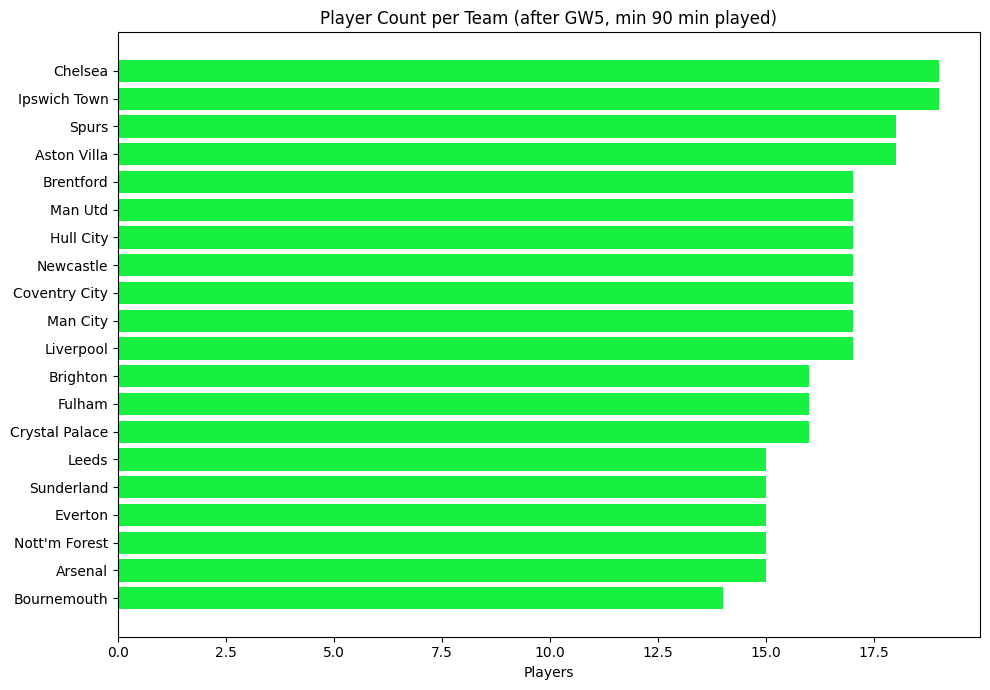

In [3]:
# (1) Bar: number of players per team

team_counts = df["team"].value_counts().sort_values(ascending=True)
plt.figure(figsize=(10, 7))
plt.barh(team_counts.index, team_counts.values, color="#18F040")
plt.title("Player Count per Team (after GW5, min 90 min played)")
plt.xlabel("Players");
plt.tight_layout();
plt.show()

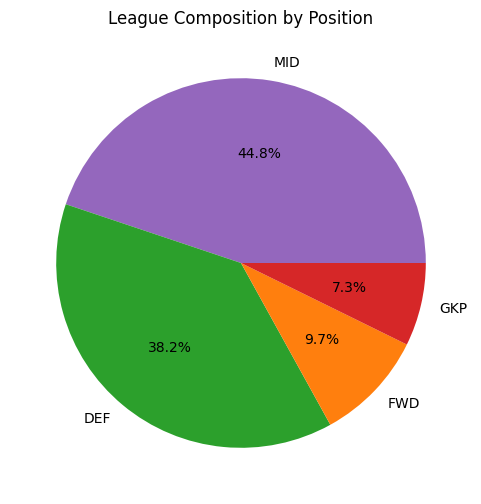

In [4]:
# (2) Pie: share of each position
pos_counts = df["position"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(pos_counts, labels=pos_counts.index, autopct="%1.1f%%", colors=["#9467bd", "#2ca02c", "#ff7f0e", "#d62728"])
plt.title("League Composition by Position");
plt.show()

In [5]:
# (3) Treemap: team -> position, sized by player count
fig = px.treemap(df, path=["team", "position"], title="Players per Team, split by Position", color="position", color_discrete_sequence=px.colors.qualitative.Set3)
fig.show()

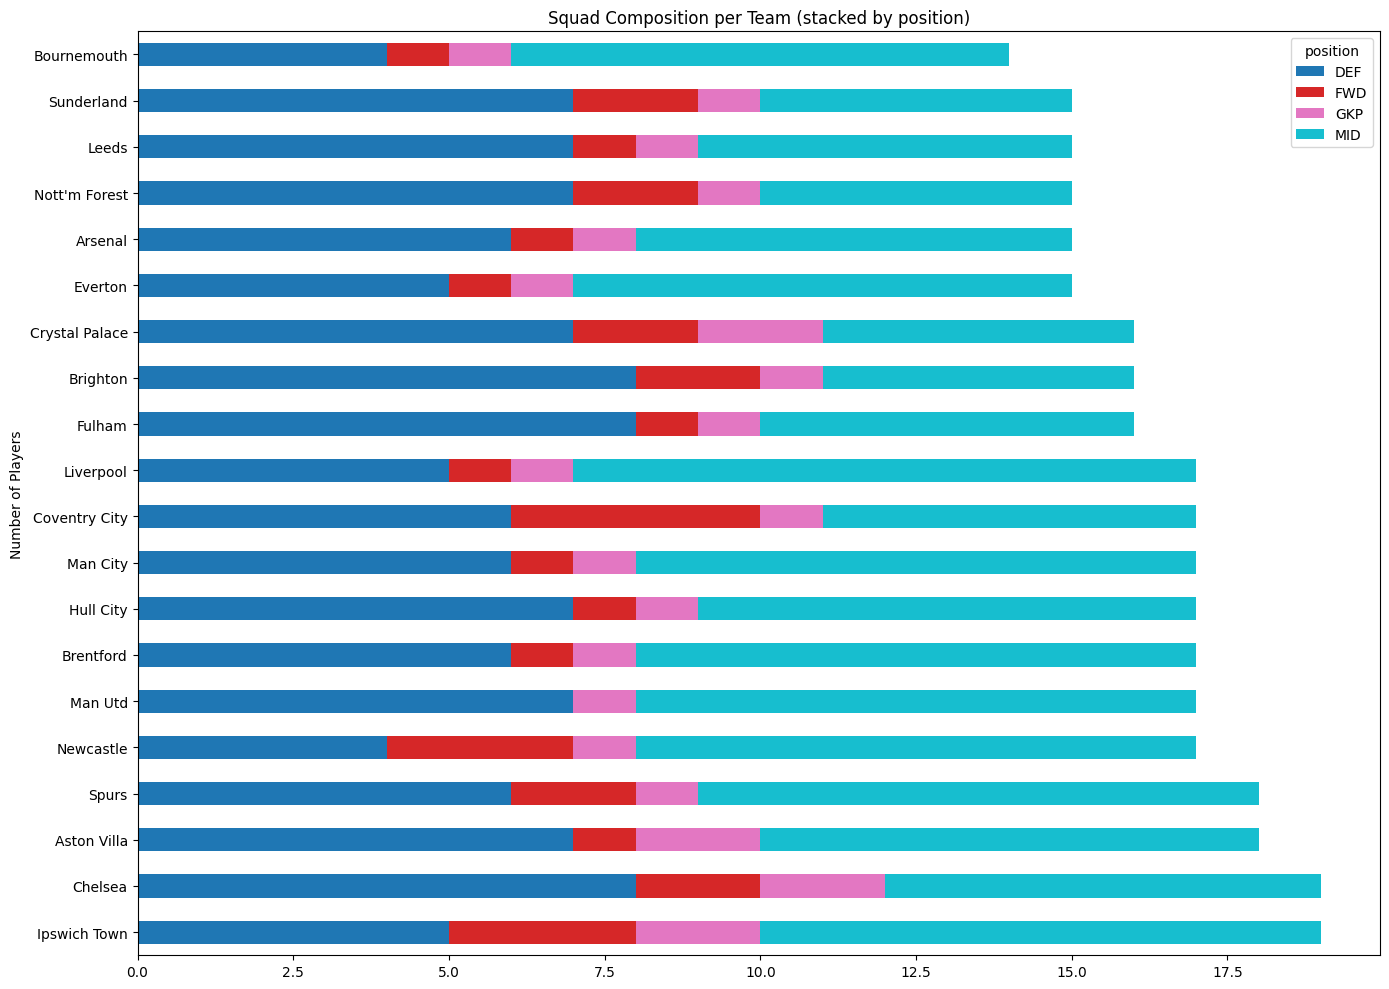

In [6]:
# (4) Stacked bar: each team's squad stacked by position (counts)
stacked = pd.crosstab(df["team"], df["position"])
stacked = stacked.loc[stacked.sum(axis=1).sort_values(ascending=False).index]
stacked.plot(kind="barh", stacked=True, figsize=(14, 10), colormap="tab10", title="Squad Composition per Team (stacked by position)")
plt.ylabel("Number of Players");
plt.tight_layout();
plt.show()

In [7]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="The default of observed=False is deprecated"
)

# (5) Sunburst: team -> position -> price_band, sized by count
fig = px.sunburst(df, path=["team", "position", "price_band"],  title="Hierarchy: Team > Position > Price Band (player counts)")
fig.show(renderer="iframe")


In [8]:
df["position"] = df["position"].replace("GKP", "GK")

In [9]:
# (6) SANKEY: flow of players  team -> position
flow = pd.crosstab(df["team"], df["position"]).stack().reset_index(name="count")
flow = flow[flow["count"] > 0]
teams_l = sorted(df["team"].unique()); pos_l = ["GK", "DEF", "MID", "FWD"]
nodes = teams_l + pos_l; idx = {n: i for i, n in enumerate(nodes)}
fig = go.Figure(go.Sankey(node=dict(label=nodes, pad=15, thickness=20), link=dict(source=[idx[t] for t in flow["team"]], target=[idx[p] for p in flow["position"]], value=flow["count"])))
fig.update_layout(title="Player Flow: Team -> Position");
fig.show()

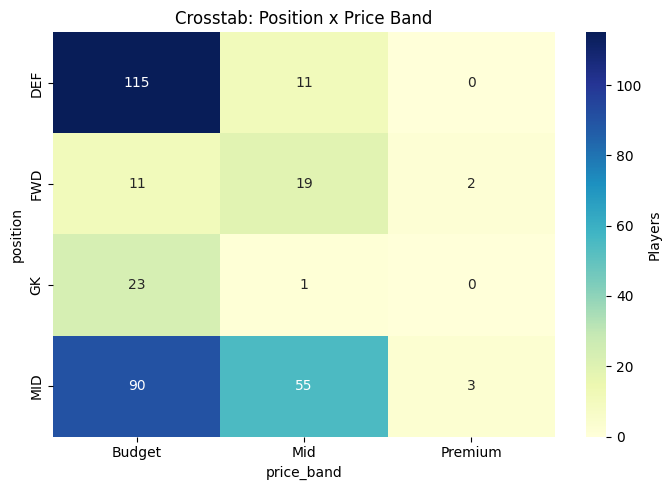

In [10]:
# (7) CROSSTAB heatmap: position x price_band (counts)
ct = pd.crosstab(df["position"], df["price_band"])
plt.figure(figsize=(7, 5))
sns.heatmap(ct, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label": "Players"})
plt.title("Crosstab: Position x Price Band");
plt.tight_layout();
plt.show()

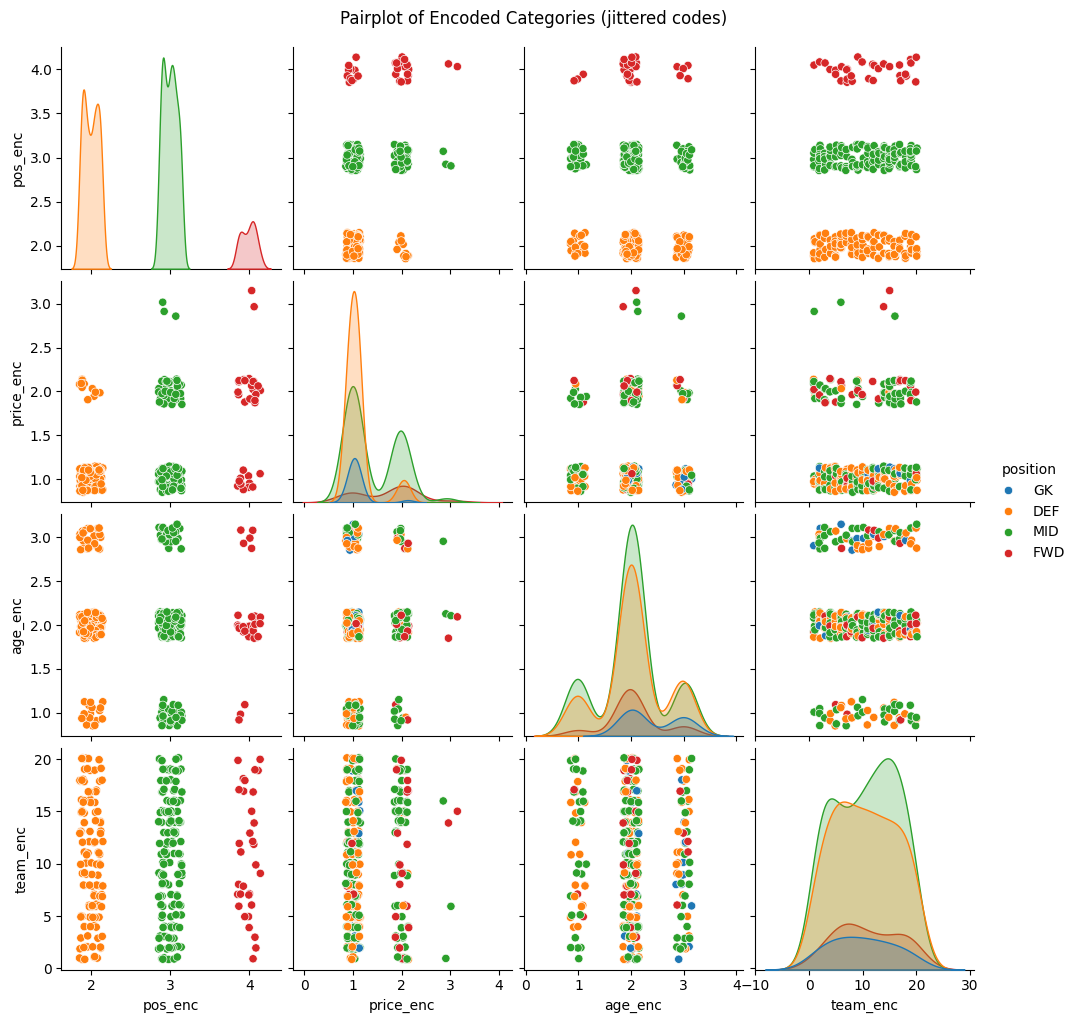

In [11]:
# (8) PAIRPLOT: on the LABEL-ENCODED categories
enc = df[["pos_enc", "price_enc", "age_enc", "team_enc"]].copy()
enc = enc.astype(float) # Ensure all columns are numeric for jittering
enc = enc + np.random.uniform(-0.15, 0.15, size=enc.shape)
enc["position"] = df["position"]
sns.pairplot(enc, hue="position", palette="tab10", diag_kind="kde")
plt.suptitle("Pairplot of Encoded Categories (jittered codes)", y=1.02)
plt.show()

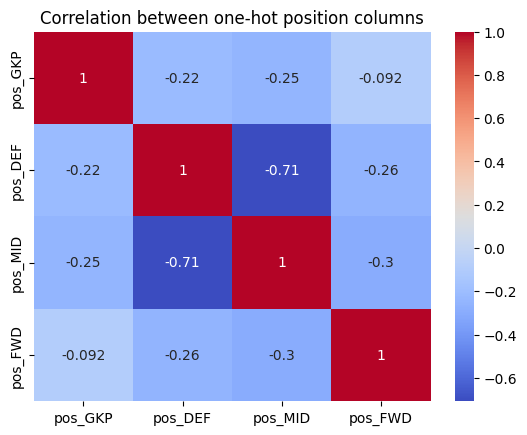

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation of dummy columns
corr = position_one_hot[["pos_GKP","pos_DEF","pos_MID","pos_FWD"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation between one-hot position columns")
plt.show()